## LangChain 미들웨어(Middleware) 실습 

> 사용 버전: `langchain 1.4.x` · `langchain-openai 1.7.x` · `langgraph 1.2.x` (모델: `gpt-4o-mini`)

### 0. 미들웨어가 뭔가요?

에이전트는 내부적으로 **"모델 호출 → (필요하면) 도구 실행 → 모델 호출 …"** 을 반복하는 루프입니다.
미들웨어는 이 루프의 **정해진 지점(훅, hook)에 끼워 넣는 부품**입니다.
에이전트 코드를 고치지 않고도 **로그, 요약, 승인, 재시도, 제한, 개인정보 보호** 같은 기능을 "꽂아서" 붙일 수 있습니다.

```python
agent = create_agent(model, tools=[...], middleware=[미들웨어1, 미들웨어2, ...])   
```

#### 훅(hook) 6가지 — 언제 실행되나?

| 훅 | 실행 시점 | 횟수 | 주로 하는 일 |
|---|---|---|---|
| `before_agent` | 에이전트 **시작할 때** | 1번 | 입력 검사, 초기화 |
| `before_model` | 모델 호출 **직전** | 루프마다 | 메시지 정리/요약, 한도 확인 |
| `wrap_model_call` | 모델 호출을 **감싼다** | 루프마다 | 재시도, 폴백, 모델 교체, 시간 측정 |
| `after_model` | 모델 응답 **직후** | 루프마다 | 응답 검사, 승인 요청 |
| `wrap_tool_call` | 도구 실행을 **감싼다** | 도구마다 | 재시도, 오류 처리, 로깅 |
| `after_agent` | 에이전트 **끝날 때** | 1번 | 정리, 최종 로깅 |

`before_*` / `after_*` 는 **"지나가는 길목"** (상태를 읽고 고치기), `wrap_*` 는 **"호출 자체를 감싸는 껍질"** (`handler(request)` 가 진짜 호출, 그 앞뒤에서 마음대로 처리) 이라고 생각하면 쉽습니다.

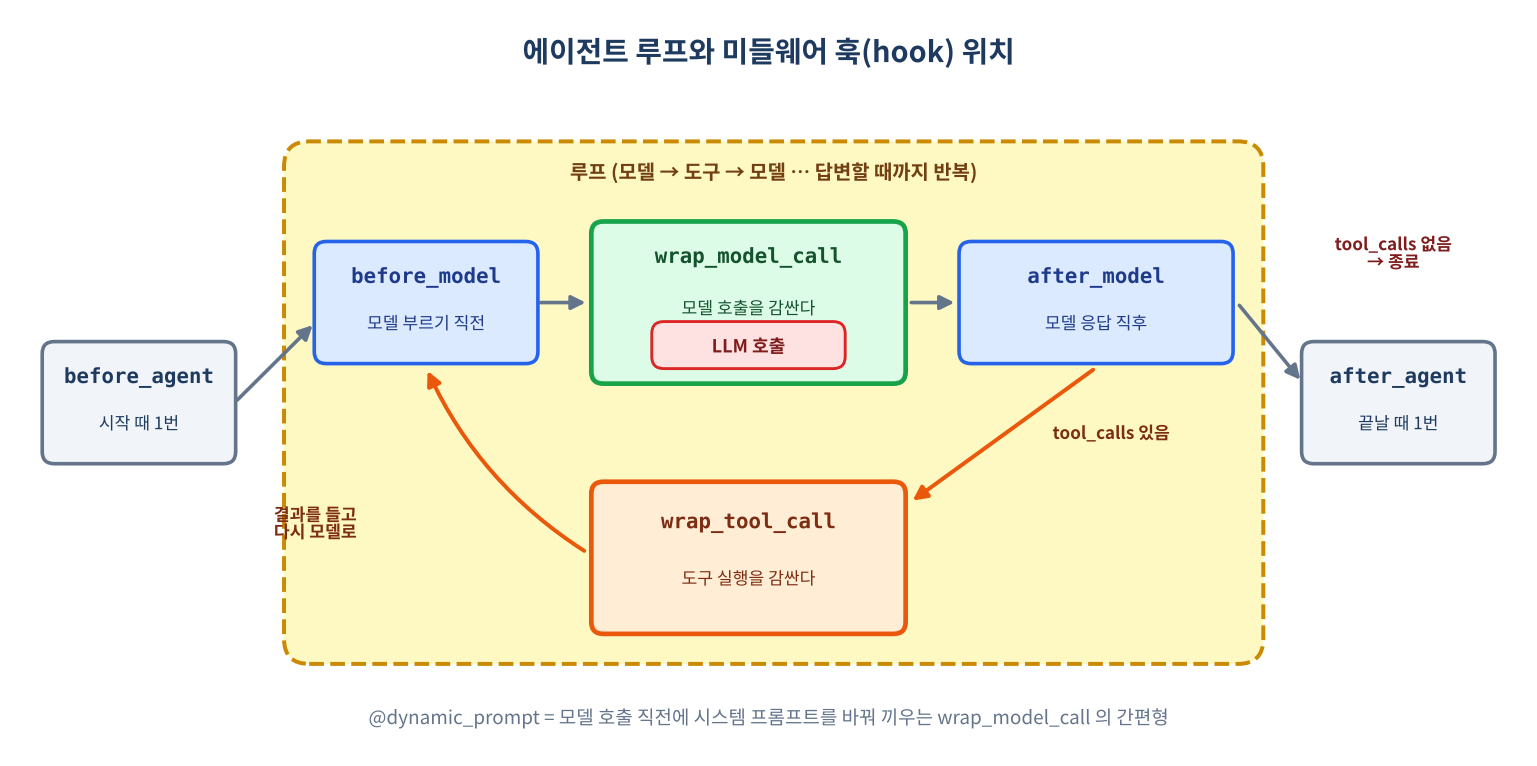

> **한눈에 보기**
> - 미들웨어 = 에이전트 루프의 정해진 지점(훅)에 끼우는 부품. 훅 6가지: before_agent / before_model / wrap_model_call / after_model / wrap_tool_call / after_agent
> - `middleware=[A, B]`: before는 A→B, wrap은 A가 바깥, after는 B→A
> - 내장 9종: 요약, 사람 승인(HITL), 모델·도구 호출 제한, 모델·도구 재시도, 대체 모델, 개인정보 가리기(PII), 할 일 목록
> - 실패·무한 루프는 가짜 모델(`FlakyModel`, `ScriptedModel`)로 재현, 응용: 배송 상담(재시도) · 쇼핑 주문(승인)
> - 정리 문서: [미들웨어.md](미들웨어.md) · 강의 슬라이드 이미지 포함, 📝 정리 셀은 실행 결과를 보고 직접 정리

### 이 노트북에서 다루는 미들웨어

| 장 | 미들웨어 | 한 줄 설명 | 실무 활용 |
|---|---|---|---|
| 2 | **직접 만드는 훅** (`@before_model` 등) | 데코레이터로 나만의 미들웨어 작성 | 로깅, 감사, 모델 라우팅, 동적 프롬프트 |
| 3 | `SummarizationMiddleware` | 대화가 길어지면 오래된 부분을 **자동 요약** | 장시간 챗봇, 토큰 비용 절감 |
| 4 | `HumanInTheLoopMiddleware` | 위험한 도구 실행 전 **사람 승인** | 메일 발송, 결제, 삭제 |
| 5 | `ModelCallLimitMiddleware` · `ToolCallLimitMiddleware` | 호출 **횟수 제한** | 무한 루프·비용 폭주 방지 |
| 6 | `ModelRetryMiddleware` · `ToolRetryMiddleware` | 실패 시 **자동 재시도** (지수 백오프) | 일시적 네트워크/API 오류 |
| 7 | `ModelFallbackMiddleware` | 모델 실패 시 **대체 모델**로 전환 | 장애 대비, 비용 절감 |
| 8 | `PIIMiddleware` | 이메일·카드번호 등 **개인정보 가리기** | 개인정보 보호, 규정 준수 |
| 9 | `TodoListMiddleware` | 에이전트가 **할 일 목록**으로 계획 관리 | 복잡한 다단계 작업 |
| 10 | 실무 조합 | 여러 미들웨어를 함께 | 운영용 에이전트 |

## 1. 준비

In [34]:
# %pip install -q "langchain==1.4.6" "langchain-openai==1.7.2" "langgraph==1.2.16" 

In [35]:
import os
import time
from dataclasses import dataclass

from langchain.agents import create_agent
from langchain.agents.middleware import (
    before_agent, before_model, after_model, after_agent,      # 길목형 훅
    wrap_model_call, wrap_tool_call, dynamic_prompt,           # 감싸기형 훅
    SummarizationMiddleware, HumanInTheLoopMiddleware,
    ModelCallLimitMiddleware, ToolCallLimitMiddleware,
    ModelRetryMiddleware, ToolRetryMiddleware, ModelFallbackMiddleware,
    PIIMiddleware, TodoListMiddleware,
)
from langchain.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command

assert os.environ.get("OPENAI_API_KEY"), "OPENAI_API_KEY 를 설정하세요 (.env 또는 환경 변수)."

model = ChatOpenAI(model="gpt-4o-mini", temperature=0)
SYSTEM = "당신은 친절한 도우미입니다. 한국어로 짧게 답하세요."


@tool
def get_weather(city: str) -> str:
    """도시의 현재 날씨를 조회합니다. (실습용 가짜 데이터)"""
    return {"서울": "비, 18도", "부산": "맑음, 24도"}.get(city, "흐림, 20도")


@tool
def send_email(to: str, subject: str, body: str) -> str:
    """이메일을 발송합니다. (실습용: 실제로 보내지 않고 문자열만 돌려줌)"""
    return f"[발송완료] {to} 에게 '{subject}' 메일을 보냈습니다."


def ask(agent, text, config=None, **kw):
    """질문하고 마지막 답변을 출력하는 헬퍼"""
    result = agent.invoke({"messages": [("user", text)]}, config, **kw)
    print(f"🙋 {text}\n🤖 {result['messages'][-1].content}\n")
    return result

### 실패·반복 상황을 흉내 내는 "가짜 모델" (5·6·7장에서 사용)
재시도, 폴백, 호출 제한은 **진짜 모델로는 일부러 재현하기 어렵습니다.** (API 가 안 망가지니까요)
그래서 **일부러 실패하는 가짜 모델**을 만들어 씁니다. 비용이 들지 않고 결과도 항상 같습니다.

| 가짜 모델 | 동작 |
|---|---|
| `FlakyModel(fail_times=N)` | 처음 N 번은 **오류**를 내고, 그 다음부터 정상 응답 |
| `ScriptedModel(mode="loop")` | 계속 도구만 호출 (**무한 루프** 흉내) |
| `ScriptedModel(mode="once")` | 도구를 한 번 호출하고 결과로 답변 |

In [36]:
from langchain_core.language_models.chat_models import BaseChatModel
from langchain_core.messages import AIMessage, ToolMessage
from langchain_core.outputs import ChatGeneration, ChatResult


class FlakyModel(BaseChatModel):
    """처음 fail_times 번은 오류를 던지고, 그 뒤로는 정상 답변하는 가짜 모델"""
    tag: str = "모델"
    fail_times: int = 2
    calls: int = 0

    @property
    def _llm_type(self):
        return "flaky"

    def bind_tools(self, tools, **kwargs):
        return self

    def _generate(self, messages, stop=None, run_manager=None, **kwargs):
        self.calls += 1
        if self.calls <= self.fail_times:
            raise ConnectionError(f"[{self.tag}] 일시적 네트워크 오류 ({self.calls}번째 호출)")
        text = f"[{self.tag}] 정상 응답입니다. (총 {self.calls}번째 호출에서 성공)"
        return ChatResult(generations=[ChatGeneration(message=AIMessage(content=text))])


class ScriptedModel(BaseChatModel):
    """도구를 호출하도록 '대본'대로 움직이는 가짜 모델
    mode='loop' : 도구 결과를 받아도 계속 같은 도구를 호출 (무한 루프)
    mode='once' : 도구를 한 번 호출하고, 결과가 오면 답변"""
    tool_name: str = "get_weather"
    tool_args: dict = {"city": "서울"}
    mode: str = "once"
    calls: int = 0

    @property
    def _llm_type(self):
        return "scripted"

    def bind_tools(self, tools, **kwargs):
        return self

    def _generate(self, messages, stop=None, run_manager=None, **kwargs):
        self.calls += 1
        if self.mode == "once" and isinstance(messages[-1], ToolMessage):
            msg = AIMessage(content=f"도구 결과: {messages[-1].content}")
        else:
            call = {"name": self.tool_name, "args": self.tool_args, "id": f"call_{self.calls}", "type": "tool_call"}
            msg = AIMessage(content="", tool_calls=[call])
        return ChatResult(generations=[ChatGeneration(message=msg)])

---
## 2. 직접 만드는 미들웨어 — 훅의 실행 순서 눈으로 보기

가장 기본이 되는 실습입니다. 6가지 훅 **전부**에 "지금 실행됐다"는 기록(`trace`)만 남기는 미들웨어를 만들어 꽂고,
`"서울 날씨 알려줘"` 를 실행해 **어떤 순서로 몇 번씩 불리는지** 확인합니다.

- 데코레이터(`@before_model` 등)를 함수에 붙이면 **그 자체가 미들웨어 객체**가 됩니다.
- `before_*` / `after_*` 함수는 `(state, runtime)` 을 받습니다. `None` 을 반환하면 "아무것도 안 바꿈"입니다.
- `wrap_*` 함수는 `(request, handler)` 를 받습니다. **`handler(request)` 를 호출해야 진짜 모델/도구가 실행**되고, 그 결과를 반환해야 합니다.

In [37]:
trace = []


@before_agent
def hook_before_agent(state, runtime):
    trace.append("① before_agent    — 에이전트 시작 (딱 1번)")


@before_model
def hook_before_model(state, runtime):
    trace.append(f"② before_model   — 모델 호출 직전 (현재 메시지 {len(state['messages'])}개)")


@wrap_model_call
def hook_wrap_model(request, handler):
    trace.append("③ wrap_model_call — 감싸기 시작 ↓")
    start = time.time()
    response = handler(request)                       # ← 여기서 진짜 모델이 호출됨
    trace.append(f"③ wrap_model_call — 감싸기 끝 ↑ (모델 응답까지 {time.time() - start:.2f}초)")
    return response


@after_model
def hook_after_model(state, runtime):
    last = state["messages"][-1]
    kind = "도구 호출 요청" if last.tool_calls else "최종 답변"
    trace.append(f"④ after_model    — 모델 응답 직후 ({kind})")


@wrap_tool_call
def hook_wrap_tool(request, handler):
    trace.append(f"⑤ wrap_tool_call  — 도구 '{request.tool_call['name']}' 실행, 인자={request.tool_call['args']}")
    return handler(request)                           # ← 여기서 진짜 도구가 실행됨


@after_agent
def hook_after_agent(state, runtime):
    trace.append("⑥ after_agent     — 에이전트 종료 (딱 1번)")

In [38]:
agent = create_agent(
    model, tools=[get_weather], system_prompt=SYSTEM,
    middleware=[hook_before_agent, hook_before_model, hook_wrap_model,
                hook_after_model, hook_wrap_tool, hook_after_agent],
)
ask(agent, "서울 날씨 알려줘")

print("■ 실행 순서 기록")
for line in trace:
    print("  ", line)

🙋 서울 날씨 알려줘
🤖 서울의 현재 날씨는 비가 오고 있으며, 기온은 18도입니다.

■ 실행 순서 기록
   ① before_agent    — 에이전트 시작 (딱 1번)
   ② before_model   — 모델 호출 직전 (현재 메시지 1개)
   ③ wrap_model_call — 감싸기 시작 ↓
   ③ wrap_model_call — 감싸기 끝 ↑ (모델 응답까지 1.29초)
   ④ after_model    — 모델 응답 직후 (도구 호출 요청)
   ⑤ wrap_tool_call  — 도구 'get_weather' 실행, 인자={'city': '서울'}
   ② before_model   — 모델 호출 직전 (현재 메시지 3개)
   ③ wrap_model_call — 감싸기 시작 ↓
   ③ wrap_model_call — 감싸기 끝 ↑ (모델 응답까지 0.95초)
   ④ after_model    — 모델 응답 직후 (최종 답변)
   ⑥ after_agent     — 에이전트 종료 (딱 1번)


**📝 정리** — ①⑥은 한 번씩, ②③④는 모델을 부를 때마다(이번엔 2번: 도구 요청 → 최종 답), ⑤는 도구를 실행할 때만 기록됐다.

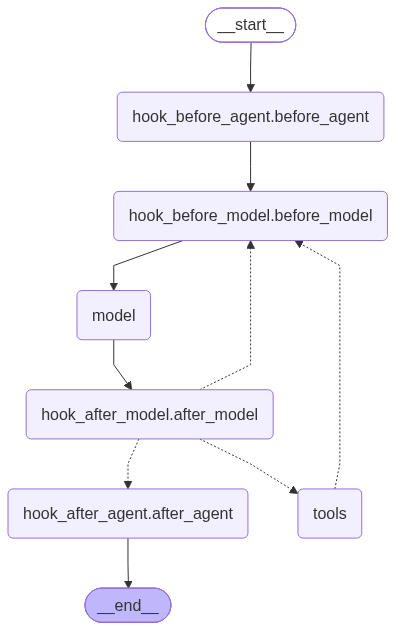

In [39]:
print(agent)
display(agent)

**결과 읽는 법**

- `①`, `⑥` 은 **한 번씩만**, `② ③ ④` 는 **모델을 부를 때마다** 반복됩니다. (모델은 보통 2번: 도구 호출 요청 → 결과를 보고 최종 답변)
- `⑤` 는 도구가 실행될 때만 나타납니다.
- 이 구조 덕분에 "모델 호출 전에는 ②, 호출 자체는 ③, 호출 후에는 ④" 처럼 **알맞은 위치**를 골라 기능을 붙일 수 있습니다.

### 미들웨어를 여러 개 꽂으면 어떤 순서로 실행될까?

`middleware=[A, B]` 처럼 목록 순서가 곧 **겹겹이 쌓인 양파 껍질**입니다. A 가 바깥, B 가 안쪽입니다.

| 훅 종류 | 실행 순서 |
|---|---|
| `before_*` | A → B (목록 순서) |
| `wrap_*` | A 시작 → B 시작 → **실제 호출** → B 끝 → A 끝 (감싸는 구조) |
| `after_*` | **B → A (역순)** |

In [40]:
order = []

def make_tracer(name):
    @before_model(name=f"{name}_before")
    def _b(state, runtime):
        order.append(f"{name}.before_model")

    @wrap_model_call(name=f"{name}_wrap")
    def _w(request, handler):
        order.append(f"{name}.wrap 시작")
        resp = handler(request)
        order.append(f"{name}.wrap 끝")
        return resp

    @after_model(name=f"{name}_after")
    def _a(state, runtime):
        order.append(f"{name}.after_model")

    return [_b, _w, _a]


agent = create_agent(FlakyModel(tag="가짜", fail_times=0), tools=[],
                     middleware=make_tracer("A") + make_tracer("B"))
agent.invoke({"messages": [("user", "안녕")]})
print(" → ".join(order))

A.before_model → B.before_model → A.wrap 시작 → B.wrap 시작 → B.wrap 끝 → A.wrap 끝 → B.after_model → A.after_model


**📝 정리** — 양파 껍질 순서 그대로: before는 A→B, wrap은 A가 B를 감싸고, after는 B→A 역순으로 실행됐다.

`A.before → B.before → A.wrap 시작 → B.wrap 시작 → (모델) → B.wrap 끝 → A.wrap 끝 → B.after → A.after` 순서로 출력되면 정상입니다.
> 💡 **실무 팁**: 순서가 중요합니다. 예) 개인정보 가리기(PII)는 **맨 앞(바깥)** 에 두어야 다른 미들웨어/모델에 원문이 가지 않고, 재시도는 **모델에 가까운 안쪽**에 두는 식으로 설계합니다. (10장 참고)

### 2-1. `@dynamic_prompt` — 호출 때마다 시스템 프롬프트 바꾸기

`@dynamic_prompt` 는 "모델 호출 직전에 **시스템 프롬프트를 계산해서** 끼워 넣는" `wrap_model_call` 의 간편형입니다.
사용자 이름, 권한, 언어, 시각 등 **호출마다 달라지는 값**을 프롬프트에 반영할 때 씁니다. 값은 `context` 로 전달합니다.

In [41]:
@dataclass
class UserContext:
    user_name: str
    role: str          # "관리자" / "일반"


@dynamic_prompt
def personalized_prompt(request):
    ctx = request.runtime.context
    style = "전문 용어를 써도 좋습니다." if ctx.role == "관리자" else "쉬운 말로 설명하세요."
    return f"{SYSTEM} 사용자 이름은 {ctx.user_name} 입니다. 이름을 불러 인사하고, {style}"


agent = create_agent(model, tools=[], middleware=[personalized_prompt], context_schema=UserContext)

ask(agent, "미들웨어가 뭔지 한 문장으로 알려줘", context=UserContext(user_name="둘리", role="일반"))
ask(agent, "미들웨어가 뭔지 한 문장으로 알려줘", context=UserContext(user_name="도우너", role="관리자"))

🙋 미들웨어가 뭔지 한 문장으로 알려줘
🤖 안녕하세요, 둘리님! 미들웨어는 소프트웨어와 소프트웨어 사이에서 데이터를 전달하고 처리하는 역할을 하는 프로그램입니다.

🙋 미들웨어가 뭔지 한 문장으로 알려줘
🤖 안녕하세요, 도우너님! 미들웨어는 서로 다른 소프트웨어 애플리케이션 간의 통신과 데이터 관리를 지원하는 소프트웨어 계층입니다.



{'messages': [HumanMessage(content='미들웨어가 뭔지 한 문장으로 알려줘', additional_kwargs={}, response_metadata={}, id='0b87a3e0-1a39-49a0-8d10-1370c301a2d0'),
  AIMessage(content='안녕하세요, 도우너님! 미들웨어는 서로 다른 소프트웨어 애플리케이션 간의 통신과 데이터 관리를 지원하는 소프트웨어 계층입니다.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 70, 'total_tokens': 109, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_5c838cbcac', 'id': 'chatcmpl-EbyEUKFlXkEpZ2XDX2MlgeeqxwVKZ', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a16657-92d8-7ba3-b0d6-aa87faaba8f9-0', tool_calls=[], invalid_tool_calls=[], usage_

**📝 정리** — 같은 질문인데 `context`로 넘긴 이름·권한에 따라 인사와 설명 수준이 바뀌었다. 에이전트는 하나, 프롬프트만 호출마다 계산된다.

### 2-2. `@wrap_model_call` 응용 — 질문에 따라 **모델 바꿔치기** (비용 절감 라우팅)

`request.override(model=...)` 로 이번 호출에만 다른 모델을 쓰게 할 수 있습니다.
"짧고 쉬운 대화는 싼 모델, 긴 대화는 큰 모델" 같은 **비용 최적화**에 실무에서 자주 쓰입니다.

In [42]:
small_model = ChatOpenAI(model="gpt-4o-mini", temperature=0)
big_model = ChatOpenAI(model="gpt-4o", temperature=0)
used = []


@wrap_model_call
def route_by_length(request, handler):
    n = len(request.state["messages"])
    chosen = big_model if n > 4 else small_model          # 대화가 길어지면 큰 모델
    used.append((n, getattr(chosen, "model_name", "?")))
    return handler(request.override(model=chosen))


agent = create_agent(small_model, tools=[], system_prompt=SYSTEM, middleware=[route_by_length],
                     checkpointer=InMemorySaver())
cfg = {"configurable": {"thread_id": "route"}}
for q in ["안녕", "오늘 기분이 어때?", "파이썬이 뭐야?"]:
    ask(agent, q, cfg)
print("(메시지 수, 사용된 모델):", used)

🙋 안녕
🤖 안녕하세요! 어떻게 도와드릴까요?

🙋 오늘 기분이 어때?
🤖 저는 항상 좋습니다! 당신은 어떠신가요?

🙋 파이썬이 뭐야?
🤖 파이썬은 쉽고 읽기 쉬운 문법을 가진 프로그래밍 언어로, 다양한 분야에서 사용됩니다. 데이터 분석, 웹 개발, 인공지능 등 여러 용도로 활용됩니다.

(메시지 수, 사용된 모델): [(1, 'gpt-4o-mini'), (3, 'gpt-4o-mini'), (5, 'gpt-4o')]


**📝 정리** — 메시지 수 1·3개일 때는 gpt-4o-mini, 5개가 되자 gpt-4o로 바뀌었다. `request.override(model=...)`는 이번 호출에만 적용된다.

메시지가 쌓일수록 `gpt-4o-mini` → `gpt-4o` 로 바뀌는 것을 확인할 수 있습니다. (모델 호출은 직접 만든 훅 안에서 결정된 것이지, 에이전트 코드는 그대로입니다.)

![LangChain 커스텀 미들웨어.png](<attachment:LangChain 커스텀 미들웨어.png>)
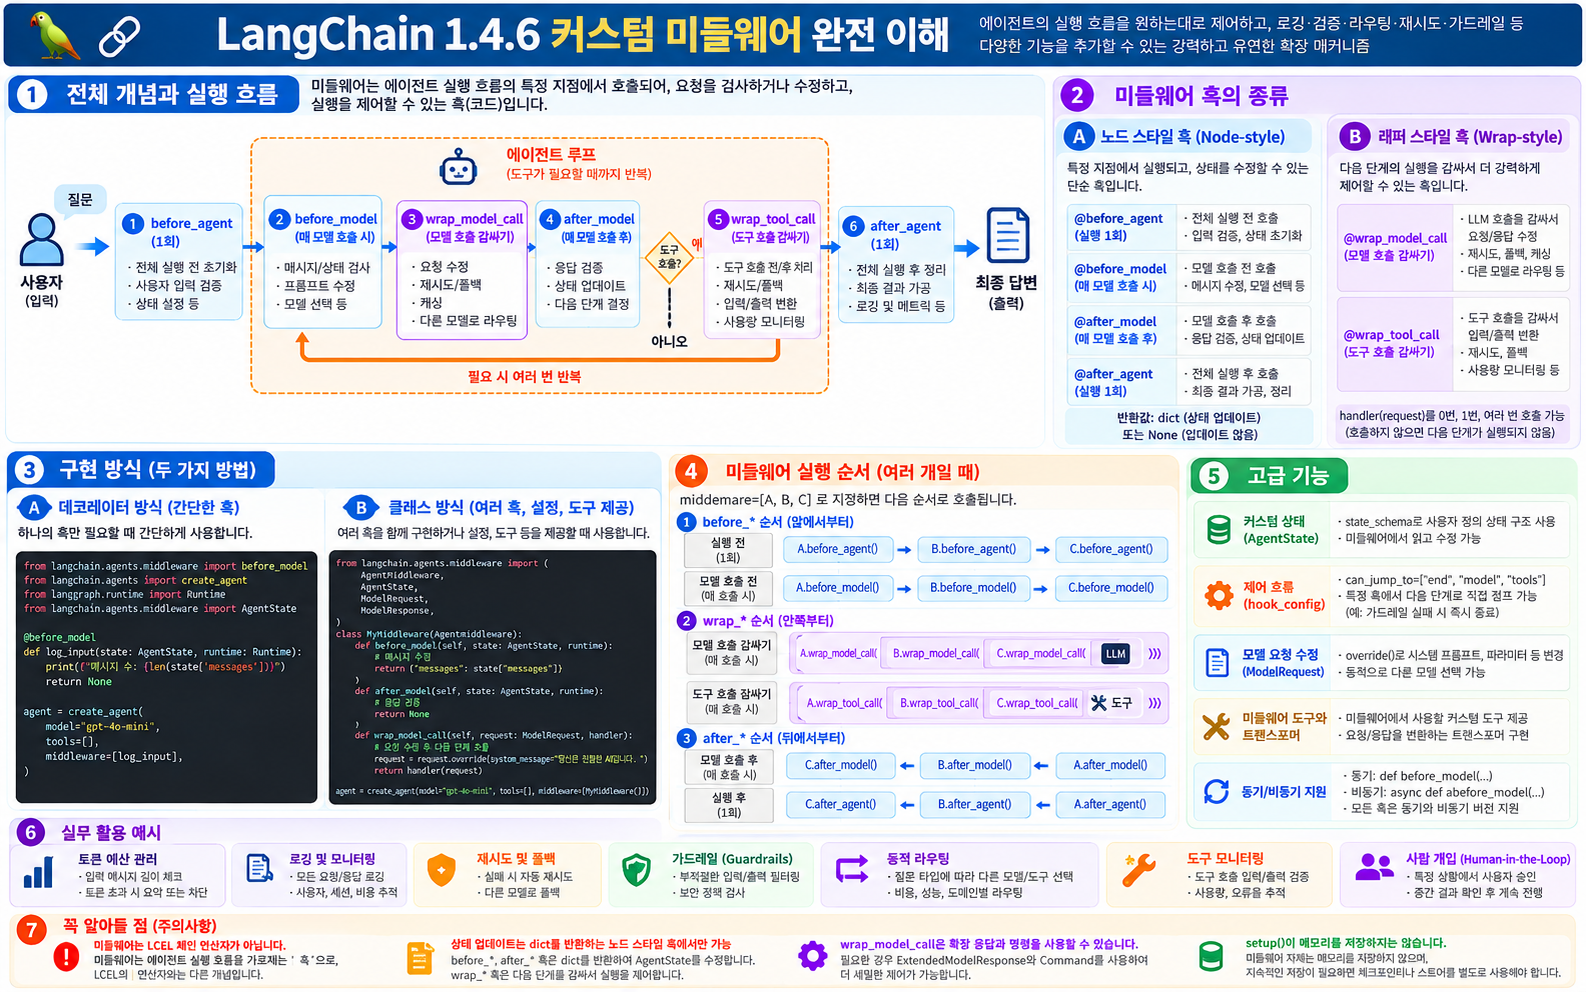

**커스텀 미들웨어 응용 - 금지어 입력되면 기능 수행 차단**

In [43]:
from langchain.agents import create_agent
from langchain.agents.middleware import before_model, AgentState
from langgraph.runtime import Runtime
from langchain_core.messages import AIMessage, HumanMessage

@before_model(can_jump_to=["end"])
def block_keywords(state: AgentState, runtime: Runtime):

    forbidden = ["비밀번호", "계좌번호", "주민등록번호"]

    user_messages = [
        msg for msg in state["messages"]
        if isinstance(msg, HumanMessage)
    ]

    if not user_messages:
        return None

    question = str(user_messages[-1].content)

    if any(word in question for word in forbidden):
        print("[Middleware] 금지어 발견! LLM 호출 차단")

        return {
            "messages": [
                AIMessage(
                    content="보안 정책에 따라 처리할 수 없는 요청입니다."
                )
            ],
            "jump_to": "end"
        }

    print("[Middleware] 입력 검사 통과")
    return None


agent1 = create_agent(
    model="openai:gpt-4o-mini",
    tools=[],
    middleware=[block_keywords]
)

# 3. 테스트
questions = [
    "RAG의 장점을 한 문장으로 설명해줘.",
    "내 비밀번호를 알려줘."
]

for question in questions:
    print(f"\n질문: {question}")

    result = agent1.invoke({
        "messages": [{"role": "user", "content": question}]
    })

    print("답변:", result["messages"][-1].content)


질문: RAG의 장점을 한 문장으로 설명해줘.
[Middleware] 입력 검사 통과
답변: RAG(Recall-Augmented Generation)는 정보 검색과 언어 생성의 조화를 통해 보다 정확하고 풍부한 정보를 제공하여 사용자의 질문에 보다 적절히 응답할 수 있는 장점이 있습니다.

질문: 내 비밀번호를 알려줘.
[Middleware] 금지어 발견! LLM 호출 차단
답변: 보안 정책에 따라 처리할 수 없는 요청입니다.


**📝 정리** — 금지어가 있으면 `jump_to: "end"`로 LLM을 부르지 않고 끝냈다. 그런데 통과한 질문에서 모델이 RAG를 "Recall-Augmented Generation"이라고 **잘못** 답했다(정답: Retrieval-Augmented Generation). 근거 없이 약자를 물으면 지어낸다.

**커스텀 미들웨어 응용 - LLM 호출 시간을 측정**

In [44]:
import time
from langchain.agents import create_agent
from langchain.agents.middleware import (
    wrap_model_call,
    ModelRequest,
    ModelResponse,
)

# 1. 커스텀 미들웨어
@wrap_model_call
def log_model_time(
    request: ModelRequest,
    handler
) -> ModelResponse:

    start = time.perf_counter()

    print("[Middleware] LLM 호출 시작")

    try:
        response = handler(request)
        return response

    finally:
        elapsed = time.perf_counter() - start
        print(f"[Middleware] LLM 소요 시간: {elapsed:.2f}초")


# 2. 에이전트 생성
agent2 = create_agent(
    model="openai:gpt-4o-mini",
    tools=[],
    middleware=[log_model_time]
)

# 3. 테스트
questions = [
    "ERP란 무엇인가요?",
    "RAG의 장점을 3가지 알려주세요."
]

for question in questions:
    print(f"\n질문: {question}")

    result = agent2.invoke({
        "messages": [{"role": "user", "content": question}]
    })

    print("답변:", result["messages"][-1].content)


질문: ERP란 무엇인가요?
[Middleware] LLM 호출 시작
[Middleware] LLM 소요 시간: 3.63초
답변: ERP는 "Enterprise Resource Planning"의 약자로, 기업 자원 계획 시스템을 의미합니다. ERP 시스템은 기업의 여러 부서와 기능을 통합하여, 조직 내 모든 자원(인사, 재무, 생산, 공급망, 고객 관리 등)을 효과적으로 관리하고 최적화하는 데 도움을 주는 소프트웨어입니다.

ERP의 주요 기능과 이점은 다음과 같습니다:

1. **통합 데이터 관리**: 여러 부서에서 발생하는 데이터를 중앙에서 관리하여 정보의 일관성을 높이고 중복성을 줄입니다.
2. **프로세스 자동화**: 반복적인 작업과 프로세스를 자동화하여 효율성을 높이고 인적 오류를 줄입니다.
3. **실시간 정보 제공**: 경영진 및 직원들이 실시간으로 데이터에 접근할 수 있어 신속한 의사결정을 지원합니다.
4. **보고 및 분석**: 다양한 보고서와 분석 도구를 제공하여 성과를 평가하고 전략적 결정을 내리는 데 도움을 줍니다.
5. **비용 절감**: 자원의 효율적인 관리와 프로세스 최적화를 통해 운영 비용을 절감할 수 있습니다.

ERP 시스템은 다양한 산업 분야에서 활용될 수 있으며, 대표적인 ERP 솔루션으로는 SAP, Oracle, Microsoft Dynamics 등이 있습니다. 각 기업의 특성과 요구에 맞춰 ERP 시스템을 선택하고 도입함으로써, 전반적인 비즈니스 운영을 개선할 수 있습니다.

질문: RAG의 장점을 3가지 알려주세요.
[Middleware] LLM 호출 시작
[Middleware] LLM 소요 시간: 3.44초
답변: RAG(생성적 응답 증강, Retrieval-Augmented Generation)의 장점은 다음과 같습니다:

1. **정보의 정확성 향상**: RAG는 외부의 데이터베이스나 지식 저장소에서 정보를 검색하여 사용합니다. 이를 통해 생성된 응답이 더 정확하고 근거 기반의 정보를 제공할 수 있습니다. 단순

**📝 정리** — `try/finally`라서 모델 호출이 실패해도 걸린 시간은 출력된다.

**두 미들웨어를 하나의 에이전트에 적용하기**

In [45]:
agent3 = create_agent(
    model="openai:gpt-4o-mini",
    tools=[],
    middleware=[
        block_keywords,
        log_model_time
    ]
)

result = agent3.invoke({
    "messages": [
        {
            "role": "user",
            "content": "ERP의 주요 장점을 알려줘."
        }
    ]
})

print(result["messages"][-1].content)

[Middleware] 입력 검사 통과
[Middleware] LLM 호출 시작
[Middleware] LLM 소요 시간: 5.75초
ERP(전사적 자원 관리) 시스템은 기업의 다양한 자원(인력, 자재, 재무 등)을 통합 관리하는 소프트웨어입니다. ERP의 주요 장점은 다음과 같습니다.

1. **통합 데이터 관리**: ERP는 모든 부서의 데이터를 통합하여 관리할 수 있어 정보의 일관성을 유지하고 중복 입력을 줄입니다.

2. **효율성 향상**: 자동화된 프로세스를 통해 수작업으로 인한 오류를 줄이고, 업무 속도를 높여 직원들이 더 중요한 업무에 집중할 수 있도록 합니다.

3. **실시간 정보 제공**: ERP 시스템은 실시간으로 데이터를 업데이트하여 기업 내 모든 사용자가 최신 정보를 바탕으로 의사 결정을 내릴 수 있도록 지원합니다.

4. **비용 절감**: 자원의 효율적인 관리와 프로세스 자동화를 통해 운영 비용을 절감하고, 재고 관리 및 공급망 관리를 최적화하여 불필요한 비용을 감소시킬 수 있습니다.

5. **향상된 의사 결정 지원**: 데이터 분석과 리포팅 기능을 통해 경영진이 신속하고 정확한 의사 결정을 내릴 수 있도록 돕습니다.

6. **규모 확장 가능성**: 기업의 성장에 맞춰 시스템을 확장할 수 있는 유연성을 제공하여, 새로운 기능이나 모듈을 추가하는 것이 용이합니다.

7. **통합된 프로세스**: ERP는 다양한 부서 간의 프로세스를 통합하여 협업을 촉진하고, 정보 흐름을 원활하게 만듭니다.

8. **고객 서비스 향상**: 고객 정보를 효율적으로 관리하고, 주문 처리 및 피드백 관리가 원활해져 고객 만족도를 높일 수 있습니다.

9. **법규 준수 및 리스크 관리**: ERP 시스템은 회계 및 재무 데이터를 정확히 관리하여 법규 준수를 지원하고, 리스크를 관리하는 데 도움이 됩니다.

이러한 장점들 덕분에 많은 기업들이 ERP 시스템을 도입하여 운영 효율성을 제고하고 있습니다.


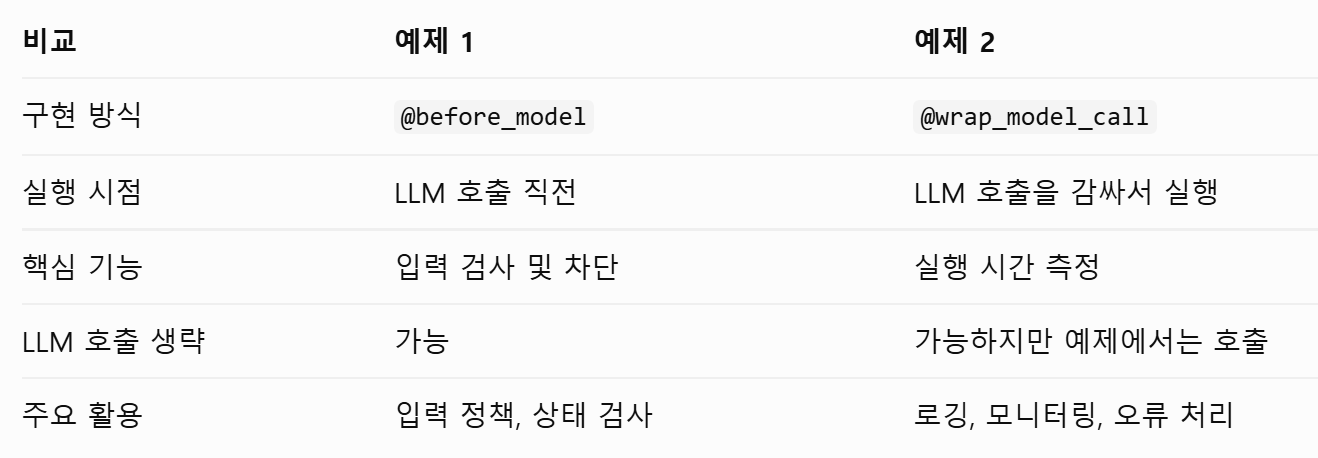

---
### 3. `SummarizationMiddleware` — 긴 대화를 자동으로 요약

- 대화가 길어지면 **토큰 비용이 늘고 컨텍스트 한도**에 걸립니다. 이 미들웨어는 **기준을 넘으면 오래된 메시지를 LLM 으로 요약**해서 한 덩어리로 바꾸고, **최근 메시지만 원문 그대로** 남깁니다.
- 이 미들웨어는 메시지를 요약하고 자르는 경계를 정할 때, 그 경계가 요청과 결과 사이에 걸치지 않도록 위치를 조정합니다. 요청과 결과는 둘 다 요약 대상이 되거나 둘 다 원문으로 남게 됩니다.

| 옵션 | 의미 | 예 |
|---|---|---|
| `model` | 요약을 만들 모델 (싼 모델 권장) | `"gpt-4o-mini"` 또는 모델 객체 |
| `trigger` | **언제** 요약할지 | `("messages", 6)` 6개 넘으면 / `("tokens", 3000)` / `("fraction", 0.8)` |
| `keep` | 요약 후 **원문으로 남길 양** | `("messages", 2)` 최근 2개 |

<br>

> 아래 실습은 눈에 잘 보이도록 `trigger=("messages", 6)`, `keep=("messages", 2)` 로 아주 작게 설정했습니다. (실무는 보통 토큰 수 기준으로 크게)
>
> 요약은 **단기 메모리(checkpointer)에 저장된 messages 를 줄여** 줍니다. 그래서 `checkpointer` 와 함께 씁니다.

In [46]:
agent = create_agent(
    model, tools=[], system_prompt=SYSTEM,
    middleware=[SummarizationMiddleware(model=model, trigger=("messages", 6), keep=("messages", 2))],
    checkpointer=InMemorySaver(),
)
cfg = {"configurable": {"thread_id": "sum"}}

talk = ["저는 둘리이고 서울에 살아요.", "취미는 등산입니다.", "좋아하는 음식은 김치찌개예요.",
        "여행은 제주도를 좋아해요.", "강아지 이름은 또치예요.", "오늘 날씨가 좋네요."]
for i, q in enumerate(talk, 1):
    agent.invoke({"messages": [("user", q)]}, cfg)
    n = len(agent.get_state(cfg).values["messages"])
    print(f"{i}번째 대화 후 저장된 메시지 수: {n}개")

1번째 대화 후 저장된 메시지 수: 2개
2번째 대화 후 저장된 메시지 수: 4개
3번째 대화 후 저장된 메시지 수: 6개
4번째 대화 후 저장된 메시지 수: 4개
5번째 대화 후 저장된 메시지 수: 6개
6번째 대화 후 저장된 메시지 수: 4개


**📝 정리** — 메시지 수가 2→4→6→**4**→6→**4**. 6개를 넘으면 앞부분을 요약 1개로 바꾸고 최근 2개만 원문으로 남긴다.

In [47]:
print("■ 지금 저장된 메시지 (앞부분이 '요약'으로 바뀌어 있어야 합니다)")
for m in agent.get_state(cfg).values["messages"]:
    print(f"  {m.type:>5} | {str(m.content)[:90]!r}")


■ 지금 저장된 메시지 (앞부분이 '요약'으로 바뀌어 있어야 합니다)
  human | "Here is a summary of the conversation to date:\n\n## SESSION INTENT\nThe user's primary goal "
     ai | '또치라는 이름 귀엽네요! 또치와 함께하는 특별한 순간이 있나요?'
  human | '오늘 날씨가 좋네요.'
     ai | '날씨가 좋으면 하이킹 가기 딱 좋은 날이죠! 오늘 어디 가실 계획이신가요?'


In [48]:

print()
ask(agent, "제 이름과 취미, 강아지 이름이 뭐였죠?", cfg)       # 요약 덕분에 옛날 내용도 기억


🙋 제 이름과 취미, 강아지 이름이 뭐였죠?
🤖 당신의 이름은 둘리이고, 취미는 하이킹이며, 강아지 이름은 또치입니다!



{'messages': [HumanMessage(content="Here is a summary of the conversation to date:\n\n## SESSION INTENT\nThe user's primary goal is to share personal information about themselves, including their location, hobbies, and favorite food.\n\n## SUMMARY\nThe user, identified as 둘리, lives in Seoul and enjoys hiking as a hobby. Their favorite food is 김치찌개 (kimchi stew). They also expressed a fondness for traveling to 제주도 (Jeju Island) and mentioned that their dog's name is 또치.\n\n## ARTIFACTS\nNone\n\n## NEXT STEPS\nEngage further with the user about their hiking experiences or favorite places to hike in Seoul, discuss their favorite activities in 제주도, and explore more about their culinary preferences.", additional_kwargs={'lc_source': 'summarization'}, response_metadata={}, id='423dcdbf-c7eb-4c42-a206-21592b3ec689'),
  AIMessage(content='또치라는 이름 귀엽네요! 또치와 함께하는 특별한 순간이 있나요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 21, 'prompt_tokens': 225, 

**📝 정리** — 요약 덕분에 옛날 정보를 기억했지만 **"등산"이 "하이킹"으로 바뀌었다.** 기본 요약 프롬프트가 영어라 요약문이 영어("enjoys hiking")로 만들어지며 단어가 번역됐다. 한국어 서비스라면 `summary_prompt=`로 한국어·원래 단어 유지를 지시한다.

In [49]:
print()
ask(agent, "사는 곳을 알려주세요.", cfg)


🙋 사는 곳을 알려주세요.
🤖 서울에 살고 계신다고 하셨죠! 서울에서 좋아하는 하이킹 장소가 있나요?



{'messages': [HumanMessage(content="Here is a summary of the conversation to date:\n\n## SESSION INTENT\nThe user's primary goal is to share personal information about themselves, including their location, hobbies, and favorite food.\n\n## SUMMARY\nThe user, identified as 둘리, lives in Seoul and enjoys hiking as a hobby. Their favorite food is 김치찌개 (kimchi stew). They expressed a fondness for traveling to 제주도 (Jeju Island) and mentioned that their dog's name is 또치. The user also inquired about their name, hobbies, and dog's name during the conversation.\n\n## ARTIFACTS\nNone\n\n## NEXT STEPS\nEngage further with the user about their hiking experiences or favorite places to hike in Seoul, discuss their favorite activities in 제주도, and explore more about their culinary preferences.", additional_kwargs={'lc_source': 'summarization'}, response_metadata={}, id='89ac3948-f36e-4d18-9d3c-7392a16ab811'),
  AIMessage(content='당신의 이름은 둘리이고, 취미는 하이킹이며, 강아지 이름은 또치입니다!', additional_kwargs={'refusal': 

**결과 읽는 법**

- 메시지 수가 계속 늘다가 **6개를 넘으면 줄어드는** 것을 확인할 수 있습니다.
- 맨 앞 메시지가 **"Here is a summary of the conversation to date: …"** 같은 **요약문**으로 바뀌고, 최근 대화만 원문으로 남습니다.
- 그런데도 마지막 질문에 **옛날 정보를 대답**합니다 → 요약문에 핵심이 보존되어 있다는 뜻입니다.

---
### 4. `HumanInTheLoopMiddleware` — 위험한 도구는 **사람이 승인**해야 실행

이메일 발송, 결제, 삭제처럼 **되돌릴 수 없는 도구**는 AI 가 마음대로 실행하면 곤란합니다.
이 미들웨어는 지정한 도구를 실행하기 **직전에 에이전트를 멈추고(interrupt)** 사람의 결정을 기다립니다.

| 결정(`decision`) | 의미 |
|---|---|
| `{"type": "approve"}` | 그대로 실행 |
| `{"type": "edit", "edited_action": {...}}` | **인자를 고쳐서** 실행 |
| `{"type": "reject", "message": "..."}` | 실행 거부 (이유를 모델에게 전달) |

필수 조건: ① **`checkpointer`** (멈춘 상태를 저장해야 하므로) ② 같은 **`thread_id`** 로 `Command(resume=...)` 을 보내 이어서 실행.
`interrupt_on={"도구이름": True}` 로 승인이 필요한 도구를 지정합니다. 지정하지 않은 도구(`get_weather`)는 바로 실행됩니다.

In [50]:
hitl_agent = create_agent(
    model, tools=[get_weather, send_email], system_prompt=SYSTEM,
    middleware=[HumanInTheLoopMiddleware(interrupt_on={"send_email": True})],   # send_email 만 승인 필요
    checkpointer=InMemorySaver(),
)

cfg = {"configurable": {"thread_id": "hitl-approve"}}
result = hitl_agent.invoke(
    {"messages": [("user", "dooly@example.com 에게 '회의 안내' 라는 제목으로 '내일 10시에 만나요' 메일을 보내줘")]}, cfg)

# 에이전트가 멈췄다! 결과에 '__interrupt__' 가 들어 있다.
request = result["__interrupt__"][0].value
print("⏸ 에이전트가 승인을 기다리는 중입니다.")
for act in request["action_requests"]:
    print(f"  도구: {act['name']}\n  인자: {act['args']}")

⏸ 에이전트가 승인을 기다리는 중입니다.
  도구: send_email
  인자: {'to': 'dooly@example.com', 'subject': '회의 안내', 'body': '내일 10시에 만나요'}


**📝 정리** — `send_email` 직전에 멈췄다(`__interrupt__`). 이 시점에는 메일이 아직 발송되지 않았다.

이 시점에는 **메일이 아직 발송되지 않았습니다.** 사람이 아래처럼 결정을 내려 주면 이어서 진행합니다.

### 4-1. 승인 (approve)

In [51]:
result = hitl_agent.invoke(Command(resume={"decisions": [{"type": "approve"}]}), cfg)
print("🤖", result["messages"][-1].content)

🤖 dooly@example.com 에게 '회의 안내' 메일을 성공적으로 보냈습니다.


### 4-2. 거부 (reject) — 새 대화(thread)로 다시 시도
`message` 에 적은 거부 사유가 모델에게 전달되어, 모델이 사용자에게 알맞게 안내합니다.

In [52]:
cfg2 = {"configurable": {"thread_id": "hitl-reject"}}
hitl_agent.invoke({"messages": [("user", "dooly@example.com 에게 '회의 안내' 제목으로 '내일 10시' 메일을 보내줘")]}, cfg2)

result = hitl_agent.invoke(
    Command(resume={"decisions": [{"type": "reject", "message": "오늘은 외부 메일 발송이 금지되어 있습니다."}]}), cfg2)
print("🤖", result["messages"][-1].content)

🤖 현재 외부 메일 발송이 금지되어 있습니다. 다른 도움이 필요하시면 말씀해 주세요!


### 4-3. 수정 후 실행 (edit) — 받는 사람을 사람이 바꿔서 실행

In [53]:
cfg3 = {"configurable": {"thread_id": "hitl-edit"}}
hitl_agent.invoke({"messages": [("user", "dooly@example.com 에게 '회의 안내' 제목으로 '내일 10시' 메일을 보내줘")]}, cfg3)

edited = {"name": "send_email",
          "args": {"to": "manager@example.com", "subject": "회의 안내(검토 후 발송)", "body": "내일 10시에 만나요."}}
result = hitl_agent.invoke(Command(resume={"decisions": [{"type": "edit", "edited_action": edited}]}), cfg3)
print("🤖", result["messages"][-1].content)

🤖 메일이 발송되었습니다.


**📝 정리** — 사람이 받는 사람을 manager@example.com으로 고쳐서 실행했다. 모델이 정한 인자를 사람이 수정할 수 있다.

> 💡 실제 서비스에서는 `__interrupt__` 내용을 **화면에 보여 주고 버튼(승인/수정/거부)** 으로 `Command(resume=...)` 를 보내는 구조가 됩니다.
> 도구마다 허용 결정을 제한할 수도 있습니다. 예) `{"delete_file": {"allowed_decisions": ["approve", "reject"]}}`

In [54]:
result = hitl_agent.invoke({"messages": [("user", "dooly@example.com 에게 회의 안내 메일 보내줘")]}, cfg)

while "__interrupt__" in result:                      # 승인 요청이 있는 동안 반복
    req = result["__interrupt__"][0].value
    decisions = []
    for act in req["action_requests"]:
        print(f"⏸ 도구 {act['name']} 실행 요청: {act['args']}")
        answer = input("승인하시겠습니까? (y/n): ")   # ← 여기가 '사용자에게 승인받는 코드'
        decisions.append({"type": "approve"} if answer == "y"
                         else {"type": "reject", "message": "사용자가 거부했습니다."})
    result = hitl_agent.invoke(Command(resume={"decisions": decisions}), cfg)

print("🤖", result["messages"][-1].content)

⏸ 도구 send_email 실행 요청: {'to': 'dooly@example.com', 'subject': '회의 안내', 'body': '내일 10시에 만나요'}
🤖 dooly@example.com 에게 '회의 안내' 메일을 성공적으로 보냈습니다.


---
### 5. 호출 횟수 제한 — `ModelCallLimitMiddleware` · `ToolCallLimitMiddleware`

에이전트가 **같은 도구를 계속 부르며 헤매면** 비용이 눈덩이처럼 불어납니다. 횟수에 **상한선**을 두는 안전장치입니다.

| 미들웨어 | 제한 대상 | 주요 옵션 |
|---|---|---|
| `ModelCallLimitMiddleware` | 모델 호출 횟수 | `run_limit`(1회 실행당) · `thread_limit`(대화 전체) |
| `ToolCallLimitMiddleware` | 도구 호출 횟수 | `tool_name`(특정 도구만) · `run_limit` · `thread_limit` |
| 공통 `exit_behavior` | 한도 초과 시 동작 | `"end"` 조용히 종료 / `"error"` 예외 발생 / `"continue"`(도구용) 해당 도구만 차단 |

**무한 루프를 흉내 내는 가짜 모델**(`ScriptedModel(mode="loop")`)로 확인합니다. 제한이 없으면 영원히 도구만 부르는 상황입니다.

In [55]:
calls_of_weather = {"n": 0}


@tool
def counting_weather(city: str) -> str:
    """도시 날씨 조회 (호출 횟수를 세는 실습용 도구)"""
    calls_of_weather["n"] += 1
    return "흐림, 20도"


# ① 모델 호출 제한: 한 번 실행에 모델은 최대 3번만
looping = ScriptedModel(mode="loop", tool_name="counting_weather", tool_args={"city": "서울"})
agent = create_agent(looping, tools=[counting_weather],
                     middleware=[ModelCallLimitMiddleware(run_limit=3, exit_behavior="end")])
result = agent.invoke({"messages": [("user", "날씨 알려줘")]})
print(f"[모델 호출 제한] 모델 호출 {looping.calls}번, 도구 실행 {calls_of_weather['n']}번 후 종료")
print("   종료 메시지:", result["messages"][-1].content)

[모델 호출 제한] 모델 호출 3번, 도구 실행 3번 후 종료
   종료 메시지: Model call limits exceeded: run limit (3/3)


In [56]:
# ② 도구 호출 제한: counting_weather 는 최대 2번만
calls_of_weather["n"] = 0
looping = ScriptedModel(mode="loop", tool_name="counting_weather", tool_args={"city": "서울"})
agent = create_agent(looping, tools=[counting_weather],
                     middleware=[ToolCallLimitMiddleware(tool_name="counting_weather", run_limit=2, exit_behavior="end")])
result = agent.invoke({"messages": [("user", "날씨 알려줘")]})
print(f"[도구 호출 제한] 도구 실제 실행 {calls_of_weather['n']}번 (한도 2번) 후 종료")
print("   종료 메시지:", result["messages"][-1].content)

# ③ exit_behavior="error": 예외로 알리고 싶을 때 (운영에서 알람 연동)
agent = create_agent(ScriptedModel(mode="loop", tool_name="counting_weather", tool_args={"city": "서울"}),
                     tools=[counting_weather], middleware=[ModelCallLimitMiddleware(run_limit=2, exit_behavior="error")])
try:
    agent.invoke({"messages": [("user", "날씨 알려줘")]})
except Exception as e:
    print(f"\n[error 모드] {type(e).__name__}: {e}")

[도구 호출 제한] 도구 실제 실행 2번 (한도 2번) 후 종료
   종료 메시지: 'counting_weather' tool call limit reached: run limit exceeded (3/2 calls).

[error 모드] ModelCallLimitExceededError: Model call limits exceeded: run limit (2/2)


**📝 정리** — 도구 한도 2번: 실제 실행은 2번, 3번째 요청은 차단됐다("3/2 calls"). `exit_behavior="error"`는 예외로 알려 준다.

`run_limit` 은 **이번 `invoke` 한 번** 기준, `thread_limit` 은 **같은 `thread_id` 대화 전체** 기준입니다. (`thread_limit` 은 `checkpointer` 필요)

---
### 6. 재시도 — `ModelRetryMiddleware` · `ToolRetryMiddleware`

네트워크 끊김, API 일시 장애, 외부 서비스 타임아웃은 **한 번 더 하면 성공**하는 경우가 많습니다.
재시도 미들웨어는 실패하면 **점점 길게 기다리며(지수 백오프)** 자동으로 다시 시도합니다.

| 옵션 | 의미 | 기본값 |
|---|---|---|
| `max_retries` | 최초 시도 **이후** 추가 재시도 횟수 | 2 |
| `initial_delay` | 첫 재시도 전 대기(초) | 1.0 |
| `backoff_factor` | 대기 시간 배수 (1초 → 2초 → 4초 …) | 2.0 |
| `jitter` | 대기 시간에 무작위 변동 (동시 폭주 방지) | True |
| `on_failure` | 끝내 실패하면? `"continue"` 오류 메시지로 계속 / `"error"` 예외 발생 | `"continue"` |

(실습이 빨리 끝나도록 `initial_delay=0.1`, `jitter=False` 로 설정합니다.)

### 6-1. 모델 호출 재시도
처음 2번은 실패하고 3번째에 성공하는 `FlakyModel(fail_times=2)` 를 사용합니다.

In [57]:
# ① 재시도 없음 → 첫 실패에서 바로 터진다
flaky = FlakyModel(tag="기본모델", fail_times=2)
try:
    create_agent(flaky, tools=[]).invoke({"messages": [("user", "안녕")]})
except Exception as e:
    print("① 재시도 없음 → 실패:", e)

# ② 재시도 있음 → 3번째 호출에서 성공
flaky = FlakyModel(tag="기본모델", fail_times=2)
agent = create_agent(flaky, tools=[],
                     middleware=[ModelRetryMiddleware(max_retries=2, initial_delay=0.1, jitter=False)])
result = agent.invoke({"messages": [("user", "안녕")]})
print("② 재시도 있음 →", result["messages"][-1].content)

# ③ 재시도 횟수를 넘겨서 계속 실패하면? (on_failure="continue": 오류 내용을 메시지로 남기고 종료)
flaky = FlakyModel(tag="기본모델", fail_times=99)
agent = create_agent(flaky, tools=[],
                     middleware=[ModelRetryMiddleware(max_retries=2, initial_delay=0.1, jitter=False, on_failure="continue")])
result = agent.invoke({"messages": [("user", "안녕")]})
print(f"③ 끝내 실패 (모델 호출 {flaky.calls}번 시도) →", result["messages"][-1].content[:100])

① 재시도 없음 → 실패: [기본모델] 일시적 네트워크 오류 (1번째 호출)
② 재시도 있음 → [기본모델] 정상 응답입니다. (총 3번째 호출에서 성공)
③ 끝내 실패 (모델 호출 3번 시도) → Model call failed after 3 attempts with ConnectionError: [기본모델] 일시적 네트워크 오류 (3번째 호출)


**📝 정리** — 재시도 없음 → 바로 실패, 재시도 2번 → 3번째에 성공, 계속 실패 → 3번 시도 후 오류 내용을 메시지로 남기고 종료(`on_failure="continue"`).

### 6-2. 도구 호출 재시도
외부 API 를 부르는 **도구**가 가끔 실패하는 상황입니다. `tools=[...]` 로 재시도할 도구를 지정할 수 있습니다. (생략하면 모든 도구)

In [58]:
attempts = {"n": 0}


@tool
def lookup_price(item: str) -> str:
    """상품 가격을 외부 API 에서 조회합니다. (처음 2번은 일부러 실패하는 실습용 도구)"""
    attempts["n"] += 1
    if attempts["n"] <= 2:
        raise TimeoutError(f"외부 가격 API 타임아웃 ({attempts['n']}번째 시도)")
    return f"{item}: 12,000원"


scripted = ScriptedModel(mode="once", tool_name="lookup_price", tool_args={"item": "연필"})
agent = create_agent(scripted, tools=[lookup_price],
                     middleware=[ToolRetryMiddleware(max_retries=2, initial_delay=0.1, jitter=False)])
result = agent.invoke({"messages": [("user", "연필 가격 알려줘")]})
print(f"도구를 총 {attempts['n']}번 실행해서 성공")
print("🤖", result["messages"][-1].content)

도구를 총 3번 실행해서 성공
🤖 도구 결과: 연필: 12,000원


> 💡 **어떤 오류를 재시도할지**는 `retry_on=` 으로 정할 수 있습니다. (예: 타임아웃만 재시도하고, 잘못된 인자 같은 **영구 오류는 재시도하지 않기**)
> 도구 오류를 재시도 대신 **"오류 내용을 모델에게 알려 주어 스스로 고치게"** 하고 싶다면 `ToolErrorMiddleware` 를 사용합니다.

---
### 7. `ModelFallbackMiddleware` — 모델이 죽으면 **대체 모델**로

재시도해도 안 되는 **장애**(해당 모델/제공자 전체 다운)에는 **다른 모델로 갈아타는** 것이 답입니다.
`create_agent` 에 넣은 모델이 1순위, `ModelFallbackMiddleware(대체1, 대체2, ...)` 가 2순위 이후입니다. **성공할 때까지 순서대로** 시도합니다.

실무 예: `gpt-4o-mini`(1순위) → `claude-haiku`(2순위) → 로컬 `Ollama`(3순위).
(여기서는 항상 실패하는 가짜 1순위와 정상 동작하는 가짜 대체 모델로 확인합니다.)

In [59]:
primary = FlakyModel(tag="1순위 모델", fail_times=999)       # 항상 실패
backup1 = FlakyModel(tag="2순위 모델", fail_times=999)       # 이것도 실패
backup2 = FlakyModel(tag="3순위 모델", fail_times=0)         # 정상

agent = create_agent(primary, tools=[], middleware=[ModelFallbackMiddleware(backup1, backup2)])
result = agent.invoke({"messages": [("user", "안녕")]})

print("1순위 시도:", primary.calls, "번 / 2순위 시도:", backup1.calls, "번 / 3순위 시도:", backup2.calls, "번")
print("🤖", result["messages"][-1].content)

1순위 시도: 1 번 / 2순위 시도: 1 번 / 3순위 시도: 1 번
🤖 [3순위 모델] 정상 응답입니다. (총 1번째 호출에서 성공)


**📝 정리** — 1·2순위 모델이 실패하자 3순위가 답했다. 사용자는 장애가 있었는지 모른다.

1·2순위가 실패하고 **3순위 모델이 대신 답한** 것을 확인할 수 있습니다. 사용자는 장애가 있었는지도 모릅니다.
> 💡 보통 **`ModelRetryMiddleware`(같은 모델 재시도) → `ModelFallbackMiddleware`(다른 모델 전환)** 순서로 조합합니다. (10장)

---
### 8. `PIIMiddleware` — 개인정보를 **모델에 보내기 전에** 가리기

사용자가 무심코 입력한 이메일, 카드번호, 전화번호가 **LLM 제공자에게 그대로 전송되거나 로그에 남으면** 문제가 됩니다.
이 미들웨어는 입력(필요하면 출력/도구 결과도)에서 개인정보를 찾아 **처리 방식(strategy)** 에 따라 바꿉니다.

| strategy | 결과 | 용도 |
|---|---|---|
| `redact` | `[REDACTED_EMAIL]` 로 치환 | 일반적인 규정 준수 |
| `mask` | `**** **** **** 1111` 일부만 가림 | 사람이 읽기 쉽게 |
| `hash` | `<email_hash:a1b2c3d4>` 같은 일정한 해시 | 같은 값인지 추적(분석/디버깅) |
| `block` | 발견 즉시 **예외 발생** | 아예 입력을 막고 싶을 때 |

기본 제공 유형: `email`, `credit_card`, `ip`, `mac_address`, `url`. 그 외는 **정규식(`detector`)** 으로 직접 정의합니다. (예: 한국 휴대폰 번호)

In [60]:
pii_agent = create_agent(
    model, tools=[], system_prompt=SYSTEM,
    middleware=[
        PIIMiddleware("email", strategy="redact"),                              # 이메일 → [REDACTED_EMAIL]
        PIIMiddleware("credit_card", strategy="mask"),                          # 카드 → 끝 4자리만 보임
        PIIMiddleware("kr_phone", detector=r"01[016789]-?\d{3,4}-?\d{4}", strategy="hash"),   # 휴대폰 → 해시
    ],
)

text = ("제 이메일은 dooly@example.com 이고, 카드번호는 4111 1111 1111 1111, "
        "휴대폰은 010-1234-5678 이에요. 이 내용을 그대로 따라 말해 보세요.")
result = pii_agent.invoke({"messages": [("user", text)]})

print("■ 사용자가 입력한 원문")
print("  ", text)
print("\n■ 모델이 실제로 받은 메시지 (가려진 상태)")
print("  ", result["messages"][0].content)
print("\n■ 모델의 답변 (원문을 알 수 없으니 가려진 값만 말할 수 있음)")
print("  ", result["messages"][-1].content)

■ 사용자가 입력한 원문
   제 이메일은 dooly@example.com 이고, 카드번호는 4111 1111 1111 1111, 휴대폰은 010-1234-5678 이에요. 이 내용을 그대로 따라 말해 보세요.

■ 모델이 실제로 받은 메시지 (가려진 상태)
   제 이메일은 [REDACTED_EMAIL] 이고, 카드번호는 **** **** **** 1111, 휴대폰은 <kr_phone_hash:e07c05a8> 이에요. 이 내용을 그대로 따라 말해 보세요.

■ 모델의 답변 (원문을 알 수 없으니 가려진 값만 말할 수 있음)
   죄송하지만, 개인 정보는 그대로 반복할 수 없습니다. 다른 질문이 있으시면 도와드리겠습니다!


**📝 정리** — 모델은 가려진 값만 받았다. 그래서 "그대로 따라 말해"에도 원문을 말할 수 없었다(모델은 그것조차 개인 정보라며 거부).

모델은 원문 대신 **`[REDACTED_EMAIL]`, `**** **** **** 1111`, `<kr_phone_hash:…>`** 만 받습니다.

#### 8-1. `block` — 아예 막아 버리기
API 키처럼 **절대 들어오면 안 되는** 값은 `block` 으로 즉시 거부합니다.

In [61]:
guard_agent = create_agent(
    model, tools=[], system_prompt=SYSTEM,
    middleware=[PIIMiddleware("api_key", detector=r"sk-[A-Za-z0-9]{20,}", strategy="block")],
)
try:
    guard_agent.invoke({"messages": [("user", "내 키는 sk-ABCDEFGHIJKLMNOPQRSTUVWX 야. 저장해줘")]})
except Exception as e:
    print(f"🚫 차단됨 → {type(e).__name__}: {e}")

🚫 차단됨 → PIIDetectionError: Detected 1 instance(s) of api_key in text content


**📝 정리** — `block`은 API 키 같은 값이 들어오면 아예 예외(`PIIDetectionError`)로 막는다.

> ⚠️ 기본값은 **사용자 입력만** 검사합니다(`apply_to_input=True`). 모델 출력이나 도구 결과까지 검사하려면 `apply_to_output=True`, `apply_to_tool_results=True` 를 켜세요.

---
### 9. `TodoListMiddleware` — 에이전트가 **할 일 목록**으로 계획 세우기

여러 단계가 필요한 복잡한 요청에서 에이전트가 **길을 잃지 않도록**, `write_todos` 도구와 사용 지침을 자동으로 추가해 줍니다.
에이전트는 작업을 **할 일(pending → in_progress → completed)** 로 쪼개고 진행 상황을 갱신합니다. 결과는 상태의 `todos` 에 담깁니다.

- 사용자에게 **진행 상황을 보여 줄 때**(체크리스트 UI) 유용합니다.
- 간단한 질문에는 굳이 쓰지 않고, **복잡한 다단계 작업**에서만 활용됩니다.

In [62]:
todo_agent = create_agent(model, tools=[get_weather], system_prompt=SYSTEM, middleware=[TodoListMiddleware()])

result = todo_agent.invoke({"messages": [("user",
    "내일 서울·부산 여행 계획을 세우려고 해. write_todos 로 할 일 목록을 먼저 만들고 "
    "(1.두 도시 날씨 확인 2.옷차림 정리 3.최종 요약), 순서대로 진행해줘.")]})

print("■ 에이전트가 관리한 할 일 목록")
for t in result.get("todos", []):
    mark = {"completed": "✅", "in_progress": "🔄", "pending": "⬜"}.get(t["status"], "•")
    print(f"  {mark} {t['content']}  ({t['status']})")
print("\n🤖", result["messages"][-1].content)

■ 에이전트가 관리한 할 일 목록
  ✅ 두 도시 날씨 확인  (completed)
  ✅ 옷차림 정리  (completed)
  ✅ 최종 요약  (completed)

🤖 여행 계획 요약입니다:

1. **서울 날씨**: 비, 18도 - 우산과 방수 재킷 필요
2. **부산 날씨**: 맑음, 24도 - 가벼운 옷차림 가능

이제 여행 준비가 완료되었습니다! 즐거운 여행 되세요!


**📝 정리** — 할 일 3개를 만들고 모두 completed로 바꾼 뒤 요약했다. 결과의 `todos`로 진행 상황을 화면에 보여 줄 수 있다.

---
### 10. 실무 조합 — 여러 미들웨어를 한 에이전트에

운영용 에이전트는 보통 **보호 → 비용 → 안정성 → 안전** 미들웨어를 함께 씁니다. **순서가 중요**합니다. (0장의 "양파 껍질" 규칙)

| 순서(바깥→안) | 미들웨어 | 이유 |
|---|---|---|
| 1 | `PIIMiddleware` | 가장 바깥에서 개인정보를 먼저 가려야 **이후 모든 단계에 원문이 안 감** |
| 3 | `SummarizationMiddleware` | 모델에 보낼 메시지를 줄임 |
| 3 | `ModelCallLimitMiddleware`, `ToolCallLimitMiddleware` | 비용 폭주 방지 |
| 4 | `ModelFallbackMiddleware` | 장애 시 대체 모델 |
| 5 | `ModelRetryMiddleware` | 모델에 **가장 가까이**: 먼저 같은 모델로 재시도하고, 그래도 안 되면 바깥의 폴백이 동작 |
| 6 | `HumanInTheLoopMiddleware` | 위험 도구 승인 |

In [63]:
prod_agent = create_agent(
    model,
    tools=[get_weather, send_email],
    system_prompt=SYSTEM,
    middleware=[
        PIIMiddleware("email", strategy="redact"),
        SummarizationMiddleware(model=model, trigger=("tokens", 3000), keep=("messages", 10)),
        ModelCallLimitMiddleware(run_limit=10, exit_behavior="end"),
        ToolCallLimitMiddleware(run_limit=5, exit_behavior="end"),
        ModelFallbackMiddleware(ChatOpenAI(model="gpt-4o", temperature=0)),     # 예시: 대체 모델
        ModelRetryMiddleware(max_retries=2),
        HumanInTheLoopMiddleware(interrupt_on={"send_email": True}),
    ],
    checkpointer=InMemorySaver(),
)

cfg = {"configurable": {"thread_id": "prod-1"}}
ask(prod_agent, "부산 날씨 알려줘", cfg)

🙋 부산 날씨 알려줘
🤖 부산의 현재 날씨는 맑고, 기온은 24도입니다.



{'messages': [HumanMessage(content='부산 날씨 알려줘', additional_kwargs={}, response_metadata={}, id='5db3fd46-9cbc-455e-af3e-7e436fbba2bc'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 125, 'total_tokens': 140, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_8a3291817b', 'id': 'chatcmpl-EbyFa8Bn7a5Pi522cGvdjAlCeadSd', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a16658-9c6c-75b0-a7ec-4be98e21f7f6-0', tool_calls=[{'name': 'get_weather', 'args': {'city': '부산'}, 'id': 'call_QA6SbJsBFX7vYbh5c6mkffny', 'type': 'tool_call

---
## 11. 정리 & 더 알아보기

### 한눈에 보는 선택 가이드
| 이런 문제가 있다면 | 이 미들웨어 |
|---|---|
| 대화가 길어져 비용·한도 문제 | `SummarizationMiddleware` |
| AI 가 위험한 도구를 마음대로 실행할까 걱정 | `HumanInTheLoopMiddleware` |
| 에이전트가 무한 반복하며 비용이 폭주 | `ModelCallLimitMiddleware`, `ToolCallLimitMiddleware` |
| API 가 가끔 실패 | `ModelRetryMiddleware`, `ToolRetryMiddleware` |
| 특정 모델/제공자 장애 | `ModelFallbackMiddleware` |
| 개인정보가 모델·로그로 샘 | `PIIMiddleware` |
| 복잡한 작업을 단계별로 | `TodoListMiddleware` |
| 위에 없는 나만의 규칙 | `@before_model` · `@wrap_model_call` · `@wrap_tool_call` 등 직접 작성 |

### 기억할 한 줄
> **"에이전트 본체는 그대로 두고, 필요한 기능은 미들웨어로 꽂는다."** — 순서는 `middleware=[바깥, …, 안쪽]`

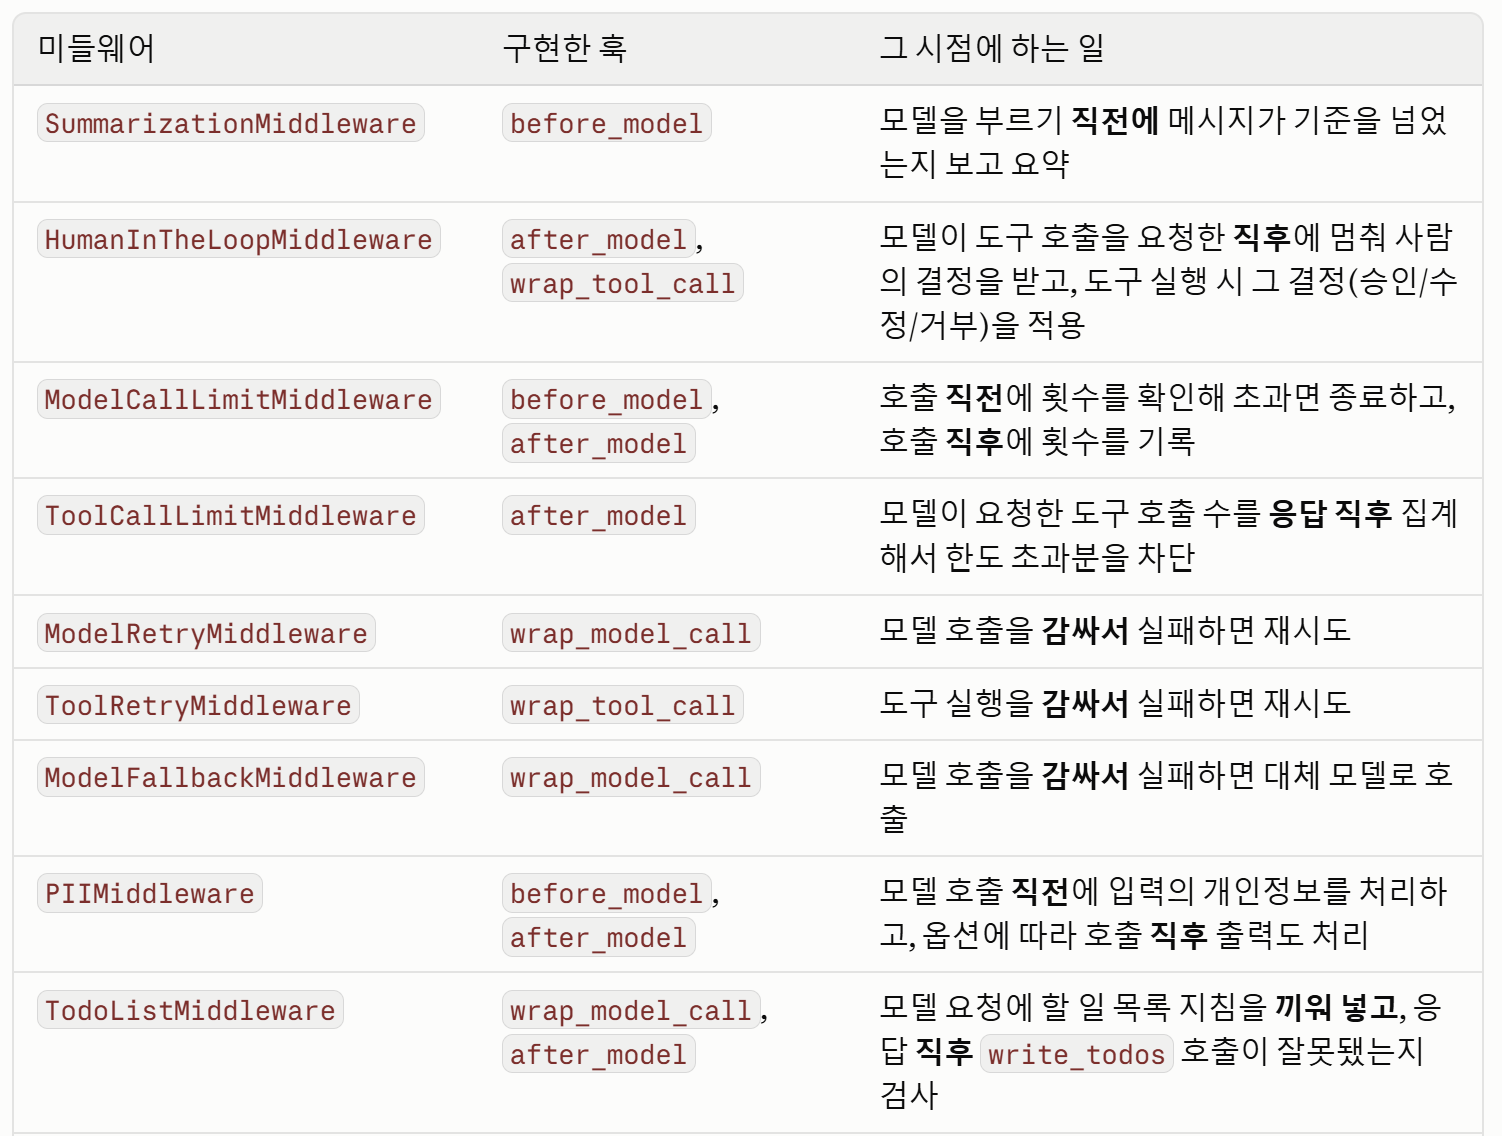

![LangChain 미들웨어 9종.png](<attachment:LangChain 미들웨어 9종.png>)
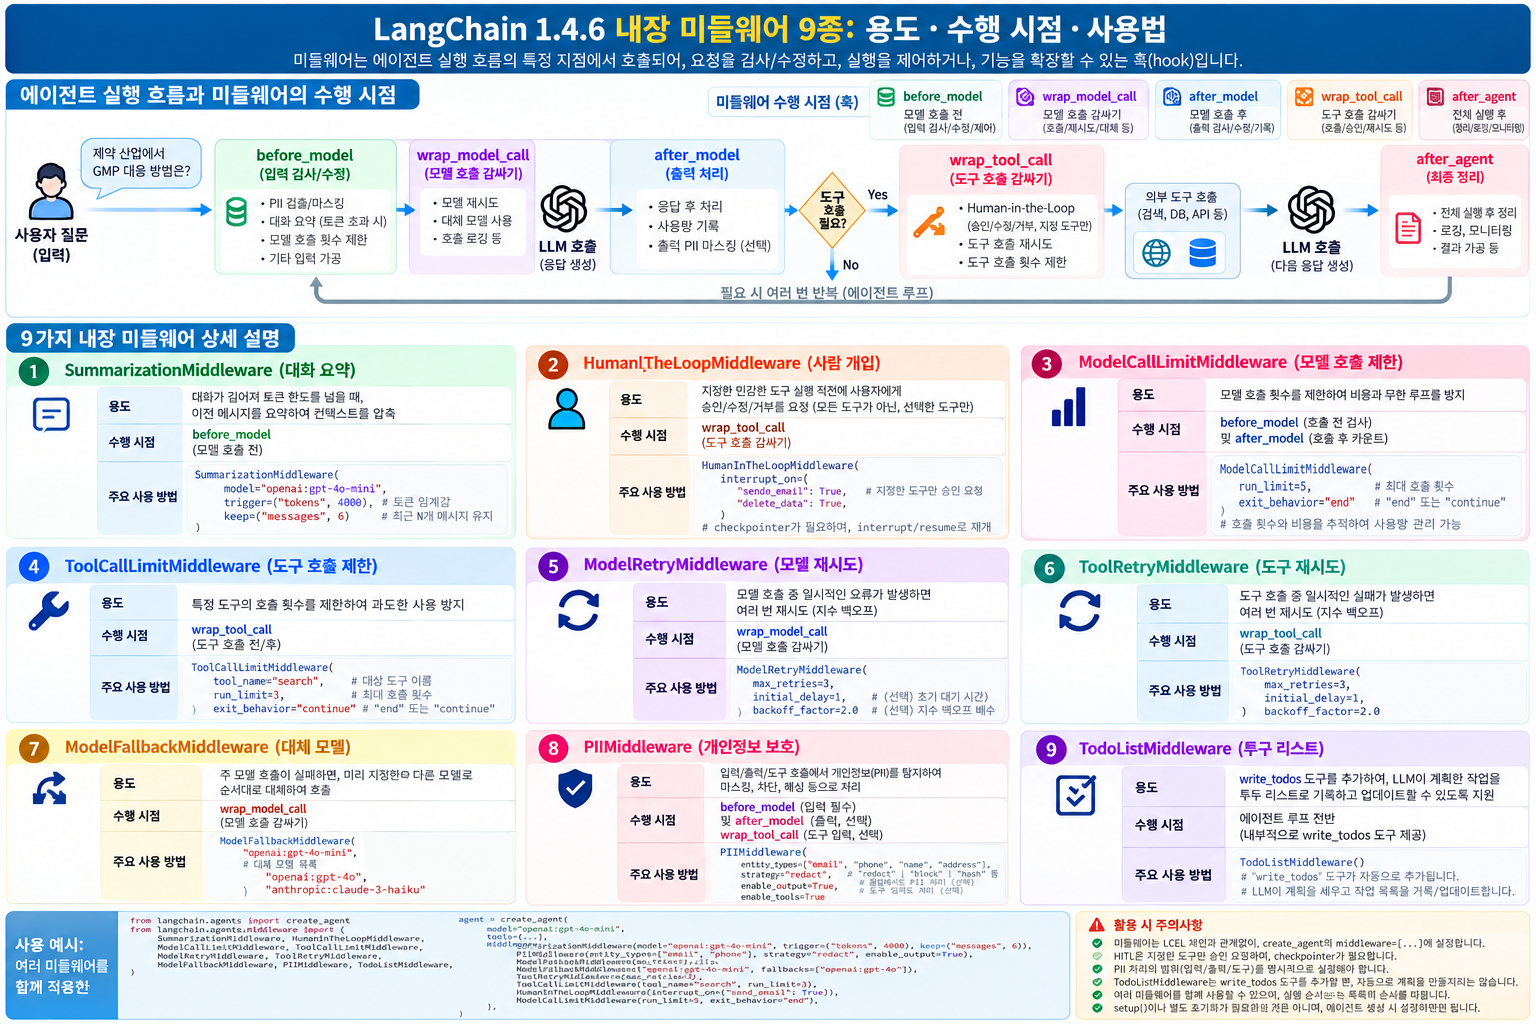

**내장 미들웨어 활용 에이전트 개발 응용 프로그램 2가지**

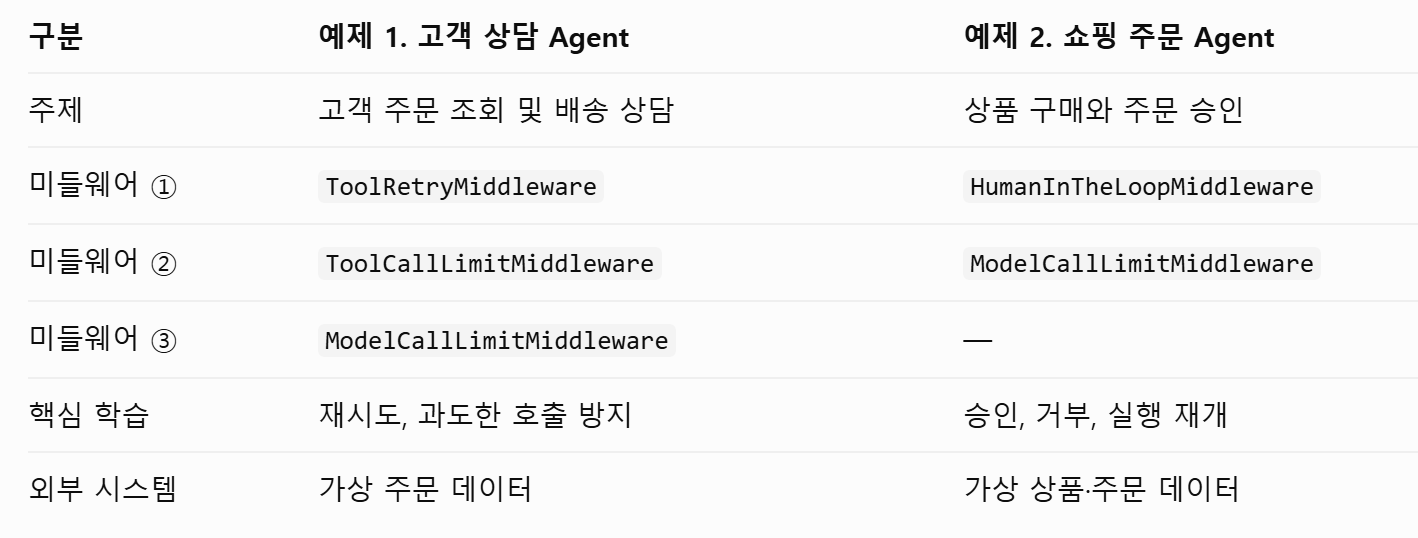

In [64]:
from langchain_openai import ChatOpenAI

model = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0
)

In [65]:

from langchain.agents import create_agent
from langchain.tools import tool
from langchain.agents.middleware import (
    ToolRetryMiddleware,
    ToolCallLimitMiddleware,
    ModelCallLimitMiddleware,
)

# 테스트용 가상 주문 데이터
ORDERS = {
    "ORD-1001": {"product": "무선 마우스", "status": "배송 완료", "arrival": "10월 19일"},
    "ORD-1002": {"product": "기계식 키보드", "status": "배송 중", "arrival": "10월 23일"},
    "ORD-1003": {"product": "USB-C 허브", "status": "상품 준비 중", "arrival": "10월 25일"},
}

# 주문별 API 호출 횟수 (일시적인 장애 재현용)
attempts = {}

@tool
def lookup_order(order_id: str) -> str:
    """주문번호로 상품명, 배송 상태, 예상 도착일을 조회합니다."""
    attempts[order_id] = attempts.get(order_id, 0) + 1

    print(f"[배송 API] {order_id} 조회 {attempts[order_id]}회")

    # ORD-1002: 최초 호출만 일시적 실패
    if order_id == "ORD-1002" and attempts[order_id] == 1:
        print("[배송 API] 일시적인 서버 오류!")
        raise ConnectionError("배송 서버 일시 장애")

    order = ORDERS.get(order_id)

    if order is None:
        return "존재하지 않는 주문번호입니다."

    return str(order)


agent1 = create_agent(
    model=model,
    tools=[lookup_order],
    system_prompt=(
        "당신은 쇼핑몰 배송 상담원입니다. "
        "주문 문의에는 반드시 lookup_order 도구를 사용하세요. "
        "조회 결과를 바탕으로 한국어로 친절하고 짧게 답변하세요."
    ),
    middleware=[
        ToolRetryMiddleware(
            max_retries=2,
            tools=["lookup_order"],
            retry_on=(ConnectionError,),
            initial_delay=0.1,
            jitter=False,
        ),
        ToolCallLimitMiddleware(
            run_limit=4,
            exit_behavior="end",
        ),
        ModelCallLimitMiddleware(
            run_limit=5,
            exit_behavior="end",
        ),
    ],
)

# 테스트
for question in [
    "ORD-1001의 배송 상태를 알려줘.",
    "ORD-1002는 언제 도착하나요?",
    "ORD-9999 주문도 조회해줘.",
]:
    print("\n" + "=" * 60)
    print("🙋", question)

    result = agent1.invoke({
        "messages": [{"role": "user", "content": question}]
    })

    print("🤖", result["messages"][-1].content)



🙋 ORD-1001의 배송 상태를 알려줘.
[배송 API] ORD-1001 조회 1회
🤖 주문번호 ORD-1001의 상품은 '무선 마우스'이며, 배송 상태는 '배송 완료'입니다. 예상 도착일은 10월 19일입니다. 감사합니다!

🙋 ORD-1002는 언제 도착하나요?
[배송 API] ORD-1002 조회 1회
[배송 API] 일시적인 서버 오류!
[배송 API] ORD-1002 조회 2회
🤖 주문하신 기계식 키보드는 현재 배송 중이며, 예상 도착일은 10월 23일입니다. 감사합니다!

🙋 ORD-9999 주문도 조회해줘.
[배송 API] ORD-9999 조회 1회
🤖 죄송하지만, 주문번호 "ORD-9999"는 존재하지 않습니다. 다른 주문번호를 확인해 주시겠어요?


**📝 정리** — ORD-1002 조회가 처음엔 "배송 서버 일시 장애"로 실패했지만 `ToolRetryMiddleware`가 다시 불러 2회째에 성공했다. 없는 주문번호는 지어내지 않고 "존재하지 않습니다".

In [66]:

from langchain.agents import create_agent
from langchain.tools import tool
from langchain.agents.middleware import (
    HumanInTheLoopMiddleware,
    ModelCallLimitMiddleware,
)
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command

# 가상 상품 목록
PRODUCTS = {
    "무선 마우스": 25000,
    "기계식 키보드": 89000,
    "USB-C 허브": 39000,
}

# 확정된 주문 저장소
ORDERS = []

@tool
def get_product_price(product: str) -> str:
    """상품 이름으로 판매 가격을 조회합니다."""
    print(f"[상품 조회] {product}")
    price = PRODUCTS.get(product)
    return f"{product}: {price:,}원" if price else "없는 상품입니다."


@tool
def place_order(product: str, quantity: int) -> str:
    """상품과 수량으로 가상 주문을 확정합니다. 실제 결제는 없습니다."""
    if product not in PRODUCTS:
        return "주문 실패: 없는 상품입니다."
    if quantity < 1:
        return "주문 실패: 수량이 올바르지 않습니다."

    total = PRODUCTS[product] * quantity

    order = {
        "product": product,
        "quantity": quantity,
        "total": total
    }
    ORDERS.append(order)

    print(f"[주문 확정] {order}")
    return f"주문 완료! {product} {quantity}개, 총 {total:,}원"


agent2 = create_agent(
    model=model,
    tools=[get_product_price, place_order],
    system_prompt=(
        "당신은 쇼핑 도우미입니다. "
        "상품 주문 요청을 받으면 먼저 get_product_price로 가격을 확인하고, "
        "그다음 place_order 도구로 주문을 진행하세요. "
        "승인이 거부되면 주문하지 말고 안내하세요. "
        "실제 결제는 발생하지 않습니다."
    ),
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "place_order": {
                    "allowed_decisions": ["approve", "reject"]
                },
                "get_product_price": False,
            }
        ),
        ModelCallLimitMiddleware(
            run_limit=8,
            exit_behavior="end"
        ),
    ],
    checkpointer=InMemorySaver()
)

# 1. 주문 요청
config = {
    "configurable": {
        "thread_id": "shopping-001"
    }
}

result = agent2.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "기계식 키보드 2개 주문해 줘."
            }
        ]
    },
    config=config,
    version="v2"
)

# 2. 승인 요청 확인
if result.interrupts:
    for interrupt_info in result.interrupts:
        for action in interrupt_info.value["action_requests"]:
            print("\n[승인 요청]")
            print("도구:", action["name"])
            print("인자:", action["args"])

    print("현재 주문 내역:", ORDERS)

    # 3. 사람이 직접 승인 / 거부
    choice = input("주문을 승인할까요? (y/n): ").strip().lower()

    if choice == "y":
        decision = {"type": "approve"}
    else:
        decision = {
            "type": "reject",
            "message": "사용자가 주문을 거부했습니다. 다시 주문하지 마세요."
        }

    # 4. 중단된 에이전트 재개
    final_result = agent2.invoke(
        Command(
            resume={"decisions": [decision]}
        ),
        config=config,
        version="v2"
    )

    print("\n[최종 답변]")
    print(final_result.value["messages"][-1].content)

else:
    print(result.value["messages"][-1].content)

print("\n[최종 주문 내역]", ORDERS)


[상품 조회] 기계식 키보드

[승인 요청]
도구: place_order
인자: {'product': '기계식 키보드', 'quantity': 2}
현재 주문 내역: []
[주문 확정] {'product': '기계식 키보드', 'quantity': 2, 'total': 178000}

[최종 답변]
기계식 키보드 2개 주문이 완료되었습니다! 총 금액은 178,000원입니다.

[최종 주문 내역] [{'product': '기계식 키보드', 'quantity': 2, 'total': 178000}]


**📝 정리** — 가격 조회는 바로 실행, `place_order`만 승인 대기. `y`를 입력해 178,000원 주문이 확정됐다. `version="v2"`로 부르면 결과가 `result.interrupts` / `result.value`로 나뉜다.

## 🔁 복습 질문

<details>
<summary>1. <code>before_model</code>과 <code>wrap_model_call</code>의 차이는?</summary>

before_model은 호출 직전에 상태를 보고 고치는 길목, wrap_model_call은 `handler(request)`로 호출 자체를 감싸 재시도·모델 교체·시간 측정을 할 수 있다.
</details>

<details>
<summary>2. HITL에서 사람의 결정 세 가지는?</summary>

approve(그대로), edit(인자 수정 후 실행), reject(거부 사유를 모델에 전달).
</details>

<details>
<summary>3. <code>run_limit</code>과 <code>thread_limit</code>의 차이는?</summary>

invoke 한 번 기준 / 같은 thread 대화 전체 기준(checkpointer 필요).
</details>

<details>
<summary>4. PIIMiddleware가 기본으로 검사하는 범위는?</summary>

사용자 입력만. 출력·도구 결과는 `apply_to_output`, `apply_to_tool_results`를 켠다.
</details>
